# 06 — Collaborative Filtering with SVD
**Event Recommendation System** · Stage 7

Learn from **everyone's behaviour**: "users who acted like you also liked…". No event text is used at all.

## The idea: matrix factorisation
Imagine the user × event table from notebook 04. Most cells are empty. **Matrix factorisation** assumes the table can be explained by a few hidden **factors** — for example *"likes tech"*, *"prefers big energetic crowds"*, *"price-sensitive"*.

- Each **user** gets a vector `p_u` saying how much they like each factor.
- Each **event** gets a vector `q_e` saying how much it has of each factor.
- Their dot product `p_u · q_e` estimates how much the user likes the event.

We never name the factors — the algorithm discovers them. This is what **SVD (Singular Value Decomposition)** means in recommender systems.

We need SVD for **two tasks**, and they need two slightly different versions:

| Task | Model | Missing cell means |
|---|---|---|
| Rating prediction (MAE, RMSE) | **Funk SVD** with biases, trained by gradient descent | *unknown* — ignore it |
| Top-10 ranking (Precision, Recall, NDCG) | **PureSVD** (truncated SVD of the engagement matrix) | *no interaction* — real information |

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_clean, temporal_split, TRAIN_END, VAL_END
from recsys.models import FunkSVD, PureSVDRecommender, GlobalMeanPredictor, ContentBasedRecommender, RandomRecommender, PopularityRecommender
from recsys.features import EventFeaturizer
from recsys.evaluation import make_ranking_task, evaluate_ranking, evaluate_rating, RankingTask
from recsys.metrics import mae, rmse
from recsys.params import load_params, update_params
from recsys.plotting import set_style, bar_labels, MODEL_COLORS, MAIN, TEXT
set_style()

users, events, inter = load_clean()
train, val, test = temporal_split(inter)
rated_train = train.dropna(subset=["rating"])
rated_val = val.dropna(subset=["rating"])
print("training ratings:", len(rated_train), "| validation ratings:", len(rated_val))

training ratings: 5056 | validation ratings: 1858


# Part A — Rating prediction with Funk SVD

## 1. The model
`predicted rating = μ + b_u + b_e + p_u · q_e`

| Term | Meaning |
|---|---|
| μ | global average rating |
| b_u | **user bias**: does this user rate higher or lower than average? |
| b_e | **event bias**: is this event rated higher or lower than average? |
| p_u · q_e | the personal match between user and event |

### Why not `numpy.linalg.svd` on the rating matrix?
Classic SVD needs a *complete* matrix. Filling missing ratings with 0 would tell the model that every unseen event was rated 0 stars — badly wrong. Instead we learn the parameters **only from the ratings we observed**, which is the approach made famous by Simon Funk in the Netflix Prize.

## 2. Training with Stochastic Gradient Descent (SGD)
For each observed rating, in random order:
1. Predict it and compute the error `e = r − prediction`.
2. Nudge every parameter a little in the direction that reduces the error:
   - `b_u ← b_u + lr · (e − reg · b_u)`
   - `b_e ← b_e + lr · (e − reg · b_e)`
   - `p_u ← p_u + lr · (e · q_e − reg · p_u)`
   - `q_e ← q_e + lr · (e · p_u − reg · q_e)`

- **lr (learning rate)**: step size. Too big → unstable; too small → slow.
- **reg (regularisation)**: pulls parameters toward 0 so the model does not memorise noise (overfitting). Very important here, because most users have only a few ratings.
- One pass over all ratings = one **epoch**.

Below is the training loop written out in plain Python, followed by a check that it gives exactly the same predictions as `recsys.models.FunkSVD`.

In [3]:
def train_funk_svd(ratings, n_factors=20, lr=0.01, reg=0.05, n_epochs=20, seed=42):
    rng = np.random.default_rng(seed)
    mu = ratings["rating"].mean()                                         # global average
    u_idx = {u: k for k, u in enumerate(ratings["user_id"].unique())}     # user_id -> row
    i_idx = {e: k for k, e in enumerate(ratings["event_id"].unique())}    # event_id -> row
    u = ratings["user_id"].map(u_idx).to_numpy()
    i = ratings["event_id"].map(i_idx).to_numpy()
    r = ratings["rating"].to_numpy(float)

    bu, bi = np.zeros(len(u_idx)), np.zeros(len(i_idx))                   # biases start at 0
    P = rng.normal(0, 0.1, (len(u_idx), n_factors))                       # small random factors
    Q = rng.normal(0, 0.1, (len(i_idx), n_factors))

    for epoch in range(n_epochs):
        for k in rng.permutation(len(r)):                                 # random order each epoch
            uu, ii = u[k], i[k]
            err = r[k] - (mu + bu[uu] + bi[ii] + P[uu] @ Q[ii])          # prediction error
            bu[uu] += lr * (err - reg * bu[uu])
            bi[ii] += lr * (err - reg * bi[ii])
            pu = P[uu].copy()                                             # keep the old p_u for q_e's update
            P[uu] += lr * (err * Q[ii] - reg * P[uu])
            Q[ii] += lr * (err * pu - reg * Q[ii])
    return mu, u_idx, i_idx, bu, bi, P, Q

mu, u_idx, i_idx, bu, bi, P, Q = train_funk_svd(rated_train)

# predict the first 5 validation ratings by hand (skip unknown users/events -> their terms are 0)
def predict_one(user, event):
    p = mu
    if user in u_idx: p += bu[u_idx[user]]
    if event in i_idx: p += bi[i_idx[event]]
    if user in u_idx and event in i_idx: p += P[u_idx[user]] @ Q[i_idx[event]]
    return float(np.clip(p, 1, 5))

sample = rated_val.head(5)
by_hand = [predict_one(u, e) for u, e in zip(sample["user_id"], sample["event_id"])]
by_class = FunkSVD(n_factors=20, lr=0.01, reg=0.05, n_epochs=20).fit(rated_train).predict(sample["user_id"], sample["event_id"])
print("by hand :", np.round(by_hand, 4))
print("by class:", np.round(by_class, 4))
print("identical:", np.allclose(by_hand, by_class))

by hand : [4.485  3.3069 4.0595 4.5505 3.788 ]
by class: [4.485  3.3069 4.0595 4.5505 3.788 ]
identical: True


**Unknown users or events.** If a validation event has no training ratings, its bias and factors do not exist, so the prediction falls back to `μ + b_u` — still personalised by the user's rating habit. A completely unknown user falls back to `μ + b_e`, and if both are unknown, `μ`.

## 3. Learning curve: watching overfitting happen
We train for 60 epochs and record the RMSE on training and validation data after every epoch.

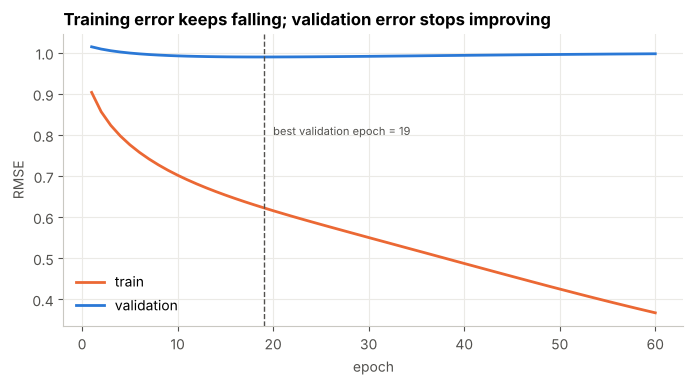

In [4]:
svd_curve = FunkSVD(n_factors=20, lr=0.01, reg=0.05, n_epochs=60).fit(rated_train, val=rated_val)
h = svd_curve.history

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(h["epoch"], h["train_rmse"], color=MODEL_COLORS["SVD"], linewidth=2, label="train")
ax.plot(h["epoch"], h["val_rmse"], color=MAIN, linewidth=2, label="validation")
best_ep = int(h.loc[h["val_rmse"].idxmin(), "epoch"])
ax.axvline(best_ep, color=TEXT, linestyle="--", linewidth=1)
ax.text(best_ep + 1, 0.8, f"best validation epoch = {best_ep}", fontsize=8, color=TEXT)
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE"); ax.legend()
ax.set_title("Training error keeps falling; validation error stops improving")
plt.show()

**Reading the curve:** training RMSE keeps dropping (the model memorises the training ratings), but validation RMSE flattens and then rises — that gap is **overfitting**. We stop at the epoch with the lowest validation RMSE (**early stopping**) and use stronger regularisation.

## 4. Hyperparameter tuning (validation set)
Grid over the number of factors and the regularisation strength; for each, we keep the best epoch.

In [5]:
rows = []
for n_factors in [5, 10, 20, 50]:
    for reg in [0.02, 0.05, 0.1, 0.2]:
        m = FunkSVD(n_factors=n_factors, lr=0.01, reg=reg, n_epochs=40).fit(rated_train, val=rated_val)
        best = m.history.loc[m.history["val_rmse"].idxmin()]
        rows.append({"n_factors": n_factors, "reg": reg, "best_epoch": int(best["epoch"]), "val_rmse": best["val_rmse"]})
svd_grid = pd.DataFrame(rows).sort_values("val_rmse")
best_svd = svd_grid.iloc[0]
svd_grid.round(4).head(8)

,n_factors,reg,best_epoch,val_rmse
4,10,0.02,18,0.9897
5,10,0.05,18,0.9897
6,10,0.10,19,0.9898
10,20,0.10,19,0.9898
9,20,0.05,19,0.9898
8,20,0.02,18,0.9899
14,50,0.10,21,0.9899
13,50,0.05,20,0.9900


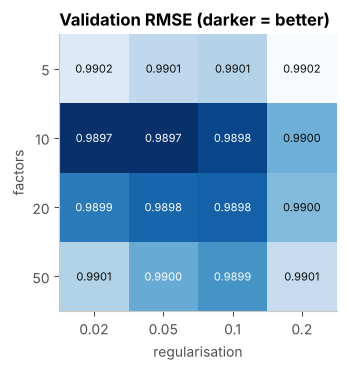

In [6]:
pivot = svd_grid.pivot(index="n_factors", columns="reg", values="val_rmse")
fig, ax = plt.subplots(figsize=(6, 3.6))
im = ax.imshow(pivot.values, cmap="Blues_r")
ax.set_xticks(range(len(pivot.columns)), pivot.columns); ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel("regularisation"); ax.set_ylabel("factors"); ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.4f}", ha="center", va="center", fontsize=8,
                color="white" if (pivot.values[i, j] - pivot.values.min()) / np.ptp(pivot.values) < 0.5 else "#0b0b0b")
ax.set_title("Validation RMSE (darker = better)")
plt.show()

## 5. Rating results on validation

In [7]:
cbf_params = load_params()["cbf"]
cbf = ContentBasedRecommender(
    EventFeaturizer(category_weight=cbf_params["category_weight"], city_weight=cbf_params["city_weight"]),
    interest_strength=cbf_params["interest_strength"], city_strength=cbf_params["city_strength"],
    neighbor_shrinkage=cbf_params["neighbor_shrinkage"]).fit(train, users, events)

svd = FunkSVD(n_factors=int(best_svd["n_factors"]), reg=float(best_svd["reg"]),
              n_epochs=int(best_svd["best_epoch"])).fit(rated_train)
rating_models = {"Global mean": GlobalMeanPredictor().fit(rated_train), "Content-Based": cbf, "SVD": svd}
pd.DataFrame({k: evaluate_rating(m, rated_val) for k, m in rating_models.items()}).T.round(4)

,MAE,RMSE
Global mean,0.8620,1.0223
Content-Based,0.8240,0.9988
SVD,0.8197,0.9897


### 5.1 Where does SVD help? Breakdown by the user's rating history
The global numbers hide an important pattern. We group validation ratings by how many ratings the user had in training.

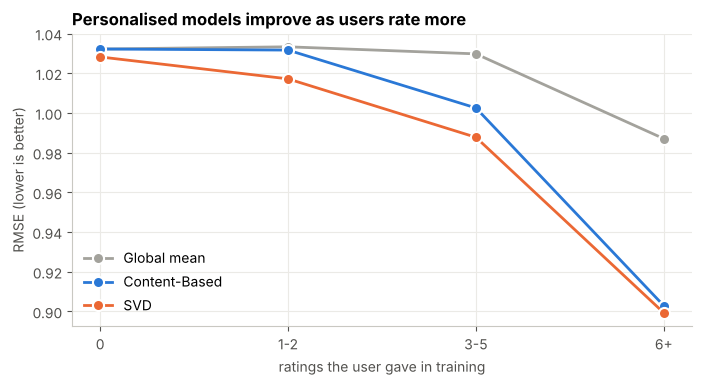

model,Content-Based,Global mean,SVD,n
previous ratings,,,,
0,1.032,1.032,1.028,566
1-2,1.032,1.033,1.017,478
3-5,1.003,1.030,0.988,412
6+,0.903,0.987,0.899,402


In [8]:
n_prev = rated_val["user_id"].map(rated_train.groupby("user_id").size()).fillna(0)
groups = pd.cut(n_prev, [-1, 0, 2, 5, 1000], labels=["0", "1-2", "3-5", "6+"])

rows = []
for g in groups.cat.categories:
    part = rated_val[groups == g]
    for name, m in rating_models.items():
        rows.append({"previous ratings": g, "model": name, "n": len(part),
                     "RMSE": rmse(part["rating"], m.predict(part["user_id"].to_numpy(), part["event_id"].to_numpy()))})
by_hist = pd.DataFrame(rows)

pv = by_hist.pivot(index="previous ratings", columns="model", values="RMSE")[list(rating_models)]
fig, ax = plt.subplots(figsize=(8, 3.8))
for name in pv.columns:                     # ordered groups -> a line with markers per model
    ax.plot(pv.index.astype(str), pv[name], marker="o", markersize=8, linewidth=2,
            color=MODEL_COLORS[name], label=name, markeredgecolor="white", markeredgewidth=1.5)
ax.set_xlabel("ratings the user gave in training")
ax.set_ylabel("RMSE (lower is better)"); ax.legend(loc="lower left")
ax.set_title("Personalised models improve as users rate more")
plt.show()
by_hist.pivot(index="previous ratings", columns="model", values="RMSE").round(3).assign(n=by_hist.groupby("previous ratings", observed=True)["n"].first())

**Reading the chart:** with no previous ratings, no model can know the user's rating habit, so everyone is close to the global mean. As history grows, the user's average (both models) and the **user bias** (SVD) become reliable, and both personalised models pull away from the baseline, SVD slightly ahead in every group. This is the honest picture of rating prediction on a young event platform: modest gains overall, real gains for active users.

# Part B — Ranking with PureSVD

## 6. Why the "missing = 0" assumption is fine for ranking
For *ranking*, we want events the user is likely to **interact with at all**. An empty cell really does carry information ("did not engage"), so we can factorise the engagement matrix directly — this is **PureSVD** (Cremonesi, Koren & Turrin, 2010), a simple and strong top-N baseline.

1. Build the engagement matrix R (users × events, values 1–4, 0 = nothing).
2. Truncated SVD keeps the top k factors: `R ≈ U Σ Vᵀ`.
3. Score for user u: `r_u V Vᵀ` — the user's row projected onto the k factors and back. Events that "go together" with what the user engaged with get high scores.

In [9]:
task = make_ranking_task(train, val, events, TRAIN_END, VAL_END)

rows = []
for k in [5, 10, 20, 50, 100]:
    m = PureSVDRecommender(n_factors=k).fit(train, users, events)
    r = evaluate_ranking(m, task).mean(numeric_only=True)
    rows.append({"n_factors": k, "precision@10": r["precision@10"], "recall@10": r["recall@10"], "ndcg@10": r["ndcg@10"]})
pure_grid = pd.DataFrame(rows)
best_k = int(pure_grid.sort_values("ndcg@10", ascending=False).iloc[0]["n_factors"])
pure_grid.round(4)

,n_factors,precision@10,recall@10,ndcg@10
0,5,0.0430,0.2239,0.1702
1,10,0.0501,0.2603,0.2111
2,20,0.0494,0.2561,0.2117
3,50,0.0476,0.2462,0.1976
4,100,0.0423,0.2202,0.1699


In [10]:
pure = PureSVDRecommender(n_factors=best_k).fit(train, users, events)
ranking_models = {"Random": RandomRecommender(), "Popularity": PopularityRecommender().fit(train),
                  "Content-Based": cbf, "SVD": pure}
overall = pd.DataFrame({k: evaluate_ranking(m, task).mean(numeric_only=True) for k, m in ranking_models.items()}).T
overall[["precision@10", "recall@10", "ndcg@10"]].round(4)

,precision@10,recall@10,ndcg@10
Random,0.0253,0.1236,0.0637
Popularity,0.0379,0.2010,0.1379
Content-Based,0.1354,0.7148,0.4431
SVD,0.0494,0.2561,0.2117


### 6.1 SVD is weak overall — but look at events that *have* history
Overall, SVD loses clearly to content-based filtering. The reason is the cold start we measured in notebook 03: most validation events had **no interactions** at the cut-off, so their SVD factors are all zero and SVD cannot rank them.

A fair question is: *on events that do have history, how good is SVD?* We re-run the evaluation with only the candidate events that had at least 5 training interactions.

warm candidate events: 29 of 75 | users with a warm relevant event: 519


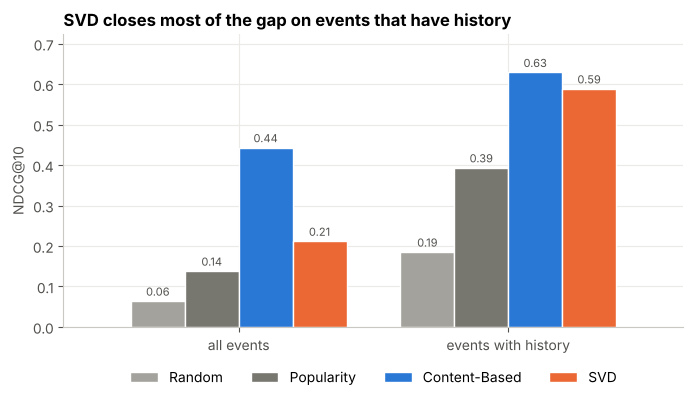

In [11]:
n_event = train.groupby("event_id").size()
warm = np.array([e for e in task.candidates if n_event.get(e, 0) >= 5])
warm_set = set(warm)
warm_task = RankingTask(warm, {u: s & warm_set for u, s in task.relevant.items() if s & warm_set}, task.seen)
print(f"warm candidate events: {len(warm)} of {len(task.candidates)} | users with a warm relevant event: {len(warm_task.relevant)}")

warm_res = pd.DataFrame({k: evaluate_ranking(m, warm_task).mean(numeric_only=True) for k, m in ranking_models.items()}).T
comp = pd.DataFrame({"all events": overall["ndcg@10"], "events with history": warm_res["ndcg@10"]})
ax = comp.T.plot.bar(color=[MODEL_COLORS[c] for c in comp.index], width=0.8, figsize=(8, 3.8), rot=0, edgecolor="white", linewidth=1)
bar_labels(ax, fmt="{:.2f}")
ax.set_ylabel("NDCG@10"); ax.set_ylim(0, comp.values.max() * 1.15)
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("SVD closes most of the gap on events that have history")
plt.show()

**This is the key result for the whole project:** overall, SVD reaches less than half of content-based NDCG, but on events with history it **closes most of the gap**. SVD's weakness is not the algorithm — it is that it cannot see new events at all. And it learns from a *different* signal (people with similar behaviour), which can capture tastes that are not written in any description. Two models that are good for different reasons are the ideal ingredients for a **hybrid** (notebook 07): use SVD where events have history, content everywhere else.

## 7. What did SVD learn? Event factors coloured by category
SVD never saw a category, a title or a city. Yet if we project each event's factor vector to 2D (t-SNE), events of the same category land together — SVD rediscovered the categories purely from *who engaged with what*.

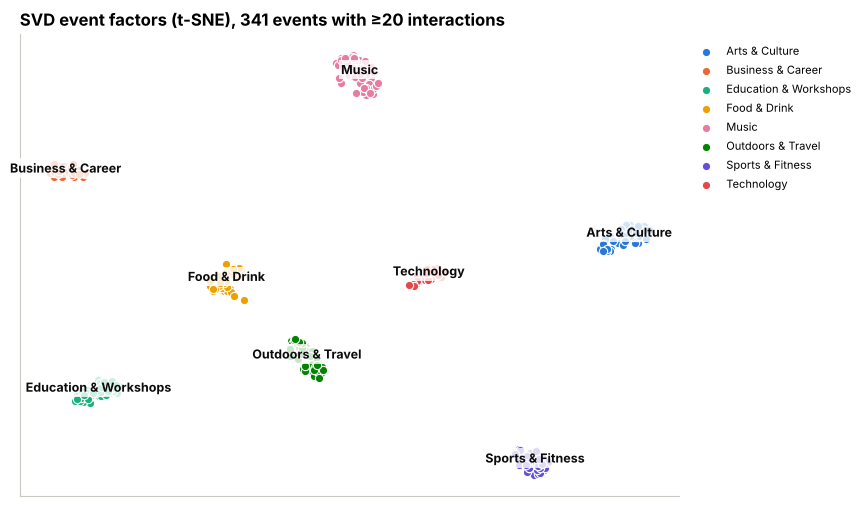

In [12]:
from sklearn.manifold import TSNE

viz = PureSVDRecommender(n_factors=10).fit(train, users, events)
n_hist = train.groupby("event_id").size().reindex(events["event_id"]).fillna(0).to_numpy()
mask = n_hist >= 20                                              # events with enough history to have stable factors
V = viz.V.T[mask]
V = V / np.linalg.norm(V, axis=1, keepdims=True)                 # compare directions, not popularity
xy = TSNE(n_components=2, metric="cosine", init="pca", perplexity=30, random_state=42).fit_transform(V)

cats = events["category"].to_numpy()[mask]
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots(figsize=(8.5, 6))
for c, color in zip(sorted(set(cats)), palette):
    pts = xy[cats == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=36, color=color, edgecolor="white", linewidth=0.8, label=c)
    cx, cy = np.median(pts, axis=0)
    ax.text(cx, cy, c, fontsize=9, fontweight="bold", color="#0b0b0b", ha="center",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1.5))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_title(f"SVD event factors (t-SNE), {mask.sum()} events with ≥20 interactions")
plt.show()

## 8. Save the chosen settings

In [13]:
params = update_params({"svd": {"n_factors": int(best_svd["n_factors"]), "reg": float(best_svd["reg"]),
                                "n_epochs": int(best_svd["best_epoch"]), "lr": 0.01},
                        "pure_svd": {"n_factors": best_k}})
{k: params[k] for k in ["svd", "pure_svd"]}

{'svd': {'n_factors': 10, 'reg': 0.02, 'n_epochs': 18, 'lr': 0.01}, 'pure_svd': {'n_factors': 20}}

## Strengths and weaknesses
| ✔ Strengths | ✘ Weaknesses |
|---|---|
| Learns hidden tastes not written anywhere | Cannot score new events or new users (cold start) |
| Uses everyone's data — "wisdom of the crowd" | Needs enough interactions; overfits with few ratings |
| Biases capture rating habits and event quality | Factors are hard to explain to a user |

### Interview questions for this stage
- *What are latent factors?* — Hidden dimensions learned from behaviour that explain why users like items. We do not label them; similar users and similar items end up with similar vectors.
- *Why can't you run normal SVD on a rating matrix?* — It needs every cell filled; treating missing ratings as 0 would teach the model that unseen items are hated. Funk SVD learns only from observed ratings.
- *What does regularisation do?* — It penalises large parameter values so the model prefers simple explanations and does not memorise noise — essential when users have few ratings.
- *Why two SVD variants?* — For ratings, a missing value is *unknown*. For ranking, a missing value is *no interaction*, which is real information, so factorising the full engagement matrix (PureSVD) is appropriate.

**Next:** `07_hybrid.ipynb`.